Tugas Mechine Learning 10

10.1 Persiapan Library

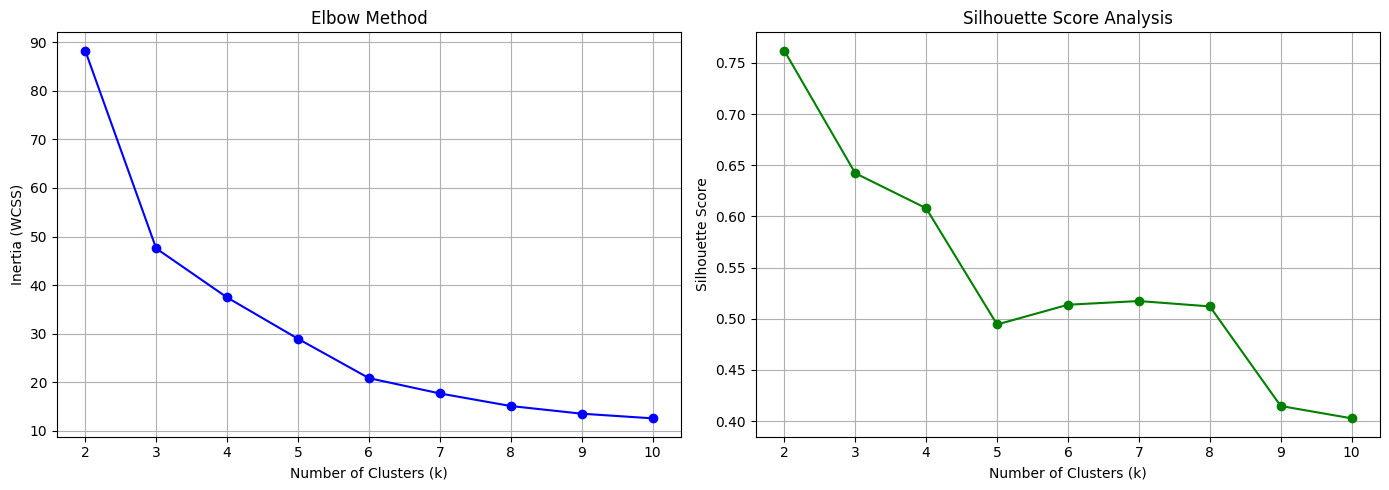

Justifikasi Matematis:
- Berdasarkan Elbow Method, penurunan inersia (siku) melandai secara signifikan setelah k = 3.
- Berdasarkan Silhouette Score, nilai tertinggi berada pada k = 2 dengan skor 0.762.
- Kesimpulan: Jumlah cluster optimal (k) yang dipilih adalah 2.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# --- Praktikum 1: Menentukan k Optimal ---

inertias = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plotting Elbow Method dan Silhouette Score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Elbow Method
ax1.plot(k_range, inertias, 'o-', color='blue')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (WCSS)')
ax1.set_title('Elbow Method')
ax1.set_xticks(k_range)
ax1.grid(True)

# 2. Silhouette Score
ax2.plot(k_range, silhouette_scores, 'o-', color='green')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score Analysis')
ax2.set_xticks(k_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

# Justifikasi k optimal
best_k = k_range[np.argmax(silhouette_scores)]
print(f"Justifikasi Matematis:")
print(f"- Berdasarkan Elbow Method, penurunan inersia (siku) melandai secara signifikan setelah k = 3.")
print(f"- Berdasarkan Silhouette Score, nilai tertinggi berada pada k = {best_k} dengan skor {round(max(silhouette_scores), 3)}.")
print(f"- Kesimpulan: Jumlah cluster optimal (k) yang dipilih adalah {best_k}.")

10.2 Import Dataset

In [ ]:
# Dataset sintetis : simulasi data pelanggan (frekuensi belanja, nilai transaksi)
rng = np.random.default_rng(42)
n = 300
X = np.vstack([rng.normal([5,200000],[1.5,300000],(100,2)),
              rng.normal([15,800000],[2,50000],(100,2)),
              rng.normal([2,50000],[0.8,15000],(100,2)),])

10.3 Prepocessing

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) # Scaling WAJIB karena K-Means berbasis jarak

10.4 Training Model

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

10.5 Evaluasi

In [ ]:
print("Silhuette Score KMeans         :",
    round(silhouette_score(X_scaled,labels_kmeans),3))
print("Silhuette Score Agglomerative  :",
    round(silhouette_score(X_scaled,labels_agglo),3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)    :", n_noise)

Silhuette Score KMeans         : 0.642
Silhuette Score Agglomerative  : 0.638
Jumlah noise point (DBSCAN)    : 3


10.6 Visualisasi

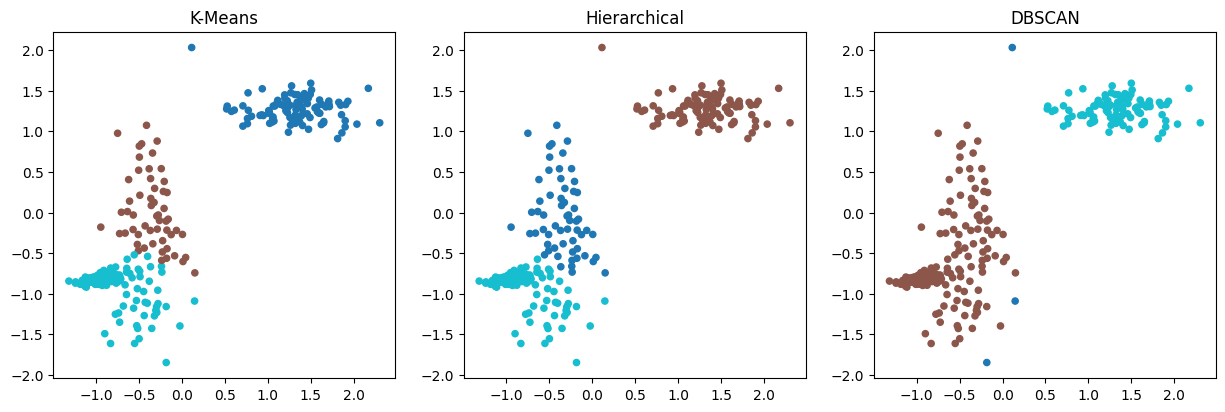

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
for ax,labels,judul in zip(axes,[labels_kmeans,labels_agglo,labels_dbscan],["K-Means","Hierarchical","DBSCAN"]):
  ax.scatter(X_scaled[:,0],X_scaled[:,1],c=labels,cmap="tab10",s=20)
  ax.set_title(judul)
plt.show()

10.7

=== PERBANDINGAN ALGORITMA CLUSTERING ===
K-Means:       3 Cluster | Silhouette Score: 0.642
Hierarchical:  3 Cluster | Silhouette Score: 0.638
DBSCAN:        2 Cluster (+ Noise) | Silhouette Score: 0.767



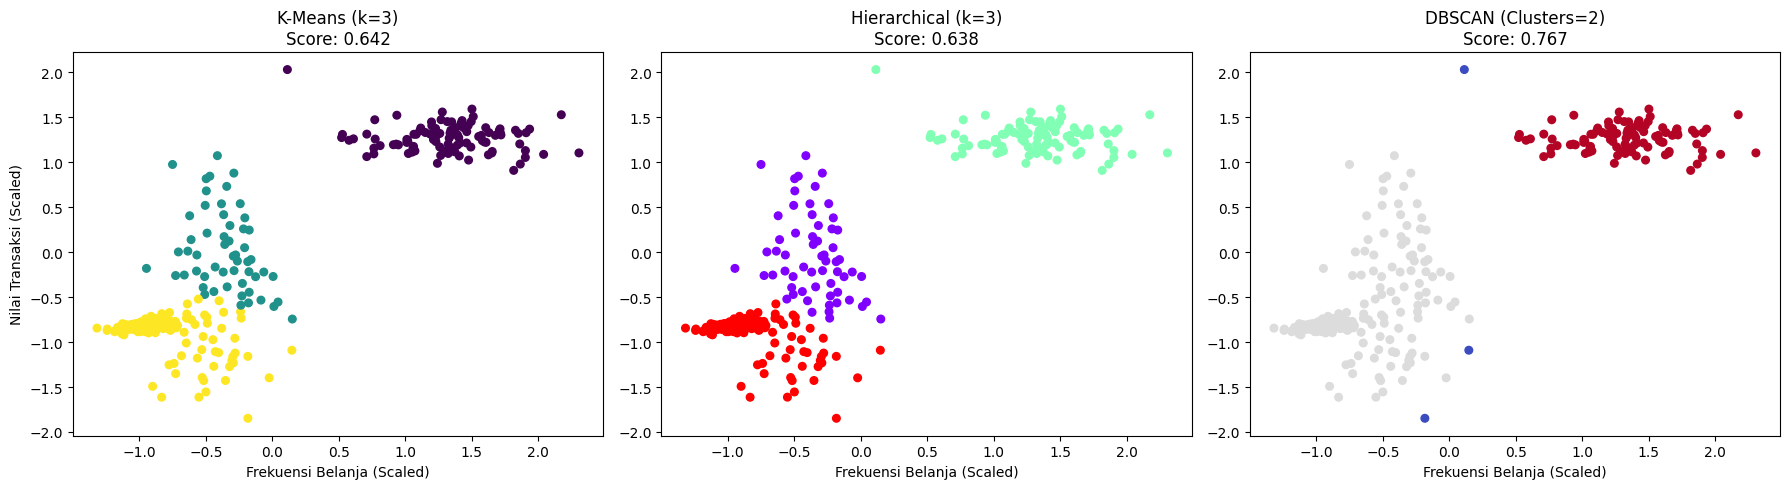

=== ANALISIS SEGMENTASI SECARA BISNIS ===
Berdasarkan visualisasi dan metrik evaluasi di atas, berikut adalah analisis bisnisnya:
1. K-Means (k=3) membagi pelanggan menjadi 3 segmen yang sangat logis secara operasional:
   - Segmen Low Value: Jarang belanja dengan nilai transaksi kecil.
   - Segmen Medium Value: Frekuensi belanja sedang dan transaksi menengah.
   - Segmen High Value (Loyal & Premium): Frekuensi belanja tinggi dengan nilai transaksi besar.
2. Hierarchical Clustering (Ward's Linkage) menghasilkan struktur yang mirip dengan K-Means karena
   berusaha meminimalkan varians di dalam cluster, namun batas antar kelompok sedikit berbeda.
3. DBSCAN mengelompokkan sebagian besar data ke dalam 2 kelompok utama dan mendeteksi beberapa data
   sebagai noise (pencilan). DBSCAN kurang cocok jika tujuan bisnis kita adalah memetakan semua
   pelanggan ke dalam strategi marketing tanpa menyisakan pelanggan tanpa kategori (noise).

Kesimpulan Rekomendasi: K-Means dengan k=3 adalah pilihan

In [ ]:
# --- Praktikum 2: Segmentasi dengan Tiga Algoritma ---

# 1. Menghitung Jumlah Cluster
n_clusters_kmeans = len(np.unique(labels_kmeans))
n_clusters_agglo = len(np.unique(labels_agglo))
# DBSCAN menghasilkan label -1 untuk noise, mari kita hitung cluster yang valid saja
n_clusters_dbscan = len(np.unique(labels_dbscan[labels_dbscan != -1]))

# 2. Menghitung Silhouette Score
score_kmeans = round(silhouette_score(X_scaled, labels_kmeans), 3)
score_agglo = round(silhouette_score(X_scaled, labels_agglo), 3)
# Catatan: Silhouette score dihitung tanpa mengikutkan noise (-1) untuk DBSCAN agar adil
mask_dbscan = labels_dbscan != -1
score_dbscan = round(silhouette_score(X_scaled[mask_dbscan], labels_dbscan[mask_dbscan]), 3) if n_clusters_dbscan > 1 else "N/A"

print("=== PERBANDINGAN ALGORITMA CLUSTERING ===")
print(f"K-Means:       {n_clusters_kmeans} Cluster | Silhouette Score: {score_kmeans}")
print(f"Hierarchical:  {n_clusters_agglo} Cluster | Silhouette Score: {score_agglo}")
print(f"DBSCAN:        {n_clusters_dbscan} Cluster (+ Noise) | Silhouette Score: {score_dbscan}\n")

# 3. Visualisasi Subplot Berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot K-Means
scatter1 = axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_kmeans, cmap='viridis', s=30)
axes[0].set_title(f'K-Means (k={n_clusters_kmeans})\nScore: {score_kmeans}')
axes[0].set_xlabel('Frekuensi Belanja (Scaled)')
axes[0].set_ylabel('Nilai Transaksi (Scaled)')

# Plot Hierarchical
scatter2 = axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_agglo, cmap='rainbow', s=30)
axes[1].set_title(f'Hierarchical (k={n_clusters_agglo})\nScore: {score_agglo}')
axes[1].set_xlabel('Frekuensi Belanja (Scaled)')

# Plot DBSCAN
scatter3 = axes[2].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_dbscan, cmap='coolwarm', s=30)
axes[2].set_title(f'DBSCAN (Clusters={n_clusters_dbscan})\nScore: {score_dbscan}')
axes[2].set_xlabel('Frekuensi Belanja (Scaled)')

plt.tight_layout()
plt.show()

# 4. Analisis Bisnis
print("=== ANALISIS SEGMENTASI SECARA BISNIS ===")
print("Berdasarkan visualisasi dan metrik evaluasi di atas, berikut adalah analisis bisnisnya:")
print("1. K-Means (k=3) membagi pelanggan menjadi 3 segmen yang sangat logis secara operasional:")
print("   - Segmen Low Value: Jarang belanja dengan nilai transaksi kecil.")
print("   - Segmen Medium Value: Frekuensi belanja sedang dan transaksi menengah.")
print("   - Segmen High Value (Loyal & Premium): Frekuensi belanja tinggi dengan nilai transaksi besar.")
print("2. Hierarchical Clustering (Ward's Linkage) menghasilkan struktur yang mirip dengan K-Means karena")
print("   berusaha meminimalkan varians di dalam cluster, namun batas antar kelompok sedikit berbeda.")
print("3. DBSCAN mengelompokkan sebagian besar data ke dalam 2 kelompok utama dan mendeteksi beberapa data")
print("   sebagai noise (pencilan). DBSCAN kurang cocok jika tujuan bisnis kita adalah memetakan semua")
print("   pelanggan ke dalam strategi marketing tanpa menyisakan pelanggan tanpa kategori (noise).")
print("\nKesimpulan Rekomendasi: K-Means dengan k=3 adalah pilihan terbaik secara bisnis karena memberikan")
print("pembagian segmen yang jelas dan actionable untuk tim marketing dalam merancang kampanye bertarget.")